In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

# X = np.random.randn(2, 3)  # shape (2, 3)
X = np.array([
	[0.25, 0.5, 0.6],
	[0.25, 0.8, 0.4],
	[0.25, 1, 0.4],
]).T

X_mean = X.mean(axis=0)
X_cen = X - X_mean

In [3]:
U, S, Vt = np.linalg.svd(X_cen, full_matrices=False)

W = Vt[0:1].T

In [4]:
X_man = X_cen @ W

In [5]:
W_pinv = np.linalg.pinv(W)
# W_mpinv = np.linalg.inv(W.T @ W) @ W.T
W_mpinv = np.linalg.inv(X_man.T @ X_man) @ X_man.T @ X_cen
X_rec_pinv = X_man @ W_pinv
X_rec_mpinv = X_man @ W_mpinv

In [ ]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Color points w.r.t. Y targets
scatter = ax.plot(
	modes[:, 0],
	modes[:, 1],
	modes[:, 2],
	c=states,
	cmap='seismic',
	alpha=1,
	s=1,
)

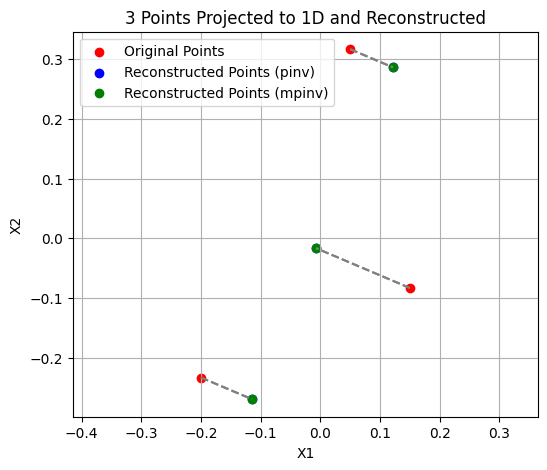

In [6]:
plt.figure(figsize=(6, 5))
plt.scatter(X_cen[:, 0], X_cen[:, 1], c='red', label='Original Points')
plt.scatter(X_rec_pinv[:, 0], X_rec_pinv[:, 1], c='blue', label='Reconstructed Points (pinv)')
plt.scatter(X_rec_mpinv[:, 0], X_rec_mpinv[:, 1], c='green', label='Reconstructed Points (mpinv)')
for i in range(3):
    plt.plot([X_cen[i, 0], X_rec_pinv[i, 0]], [X_cen[i, 1], X_rec_pinv[i, 1]], 'gray', linestyle='--')
    plt.plot([X_cen[i, 0], X_rec_mpinv[i, 0]], [X_cen[i, 1], X_rec_mpinv[i, 1]], 'gray', linestyle='--')

plt.legend()
plt.title("3 Points Projected to 1D and Reconstructed")
plt.xlabel("X1")
plt.ylabel("X2")
plt.axis('equal')
plt.grid(True)
plt.show()